### Features and RANSAC


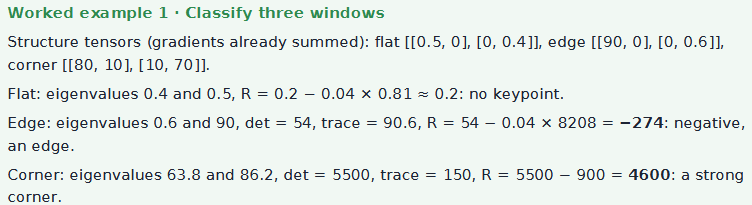

Eigenvalues and Harris response

In [1]:
import numpy as np

def classify(M, k=0.04):
    l1, l2 = np.linalg.eigvalsh(M)
    R = np.linalg.det(M) - k*np.trace(M)**2
    return l1, l2, R

for name, M in [("flat", np.array([[0.5, 0.0], [0.0, 0.4]])),
        ("edge", np.array([[90.0, 0.0], [0.0, 0.6]])),
        ("corner", np.array([[80.0, 10.0], [10.0, 70.0]]))]:
    l1, l2, R = classify(M)
    
    print(f"{name:6s}: egenvalues {l1:6.1f}, {l2:6.1f} Harris R = {R:8.1f}")

flat  : egenvalues    0.4,    0.5 Harris R =      0.2
edge  : egenvalues    0.6,   90.0 Harris R =   -274.3
corner: egenvalues   63.8,   86.2 Harris R =   4600.0


In [5]:
import cv2
from skimage import data 
img1 = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2GRAY) 
H_true = np.array([[0.90, -0.25, 80.0],
                    [0.20, 0.95, 10.0],
                    [2e-4, 1e-4, 1.0]])
img2 = cv2.warpPerspective(img1, H_true, (512, 512))
rng = np.random.default_rng(0)
img2 = np.clip(0.8 * img2 + 25 + rng.normal(0, 4, img2.shape), 0, 255).astype(np.uint8)

def harris(gray, sigma=1.5, k=0.04):
    g = gray.astype(np.float32) / 255.0
    Ix = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
    Iy = cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3)
    Sxx = cv2.GaussianBlur(Ix * Ix, (0, 0), sigma)
    Syy = cv2.GaussianBlur(Iy * Iy, (0, 0), sigma)
    Sxy = cv2.GaussianBlur(Ix * Iy, (0, 0), sigma)
    return Sxx * Syy - Sxy**2 - k * (Sxx + Syy) ** 2
def corners_from_response(R, n=300, min_dist=7):
    local_max = R == cv2.dilate(R, np.ones((2 * min_dist + 1,) * 2, np.uint8))
    ys, xs = np.nonzero(local_max & (R > 0))
    order = np.argsort(R[ys, xs])[::-1][:n]
    return np.c_[xs[order], ys[order]]
R = harris(img1)
pts = corners_from_response(R)
pts2 = corners_from_response(harris(img2))
proj = cv2.perspectiveTransform(pts.reshape(-1, 1, 2).astype(np.float32), H_true)
proj = proj.reshape(-1, 2)
inside = (proj[:, 0] > 10) & (proj[:, 0] < 502) & (proj[:, 1] > 10) & (proj[:, 1] < 502)
d = np.linalg.norm(proj[inside, None, :] - pts2[None, :, :], axis=2).min(axis=1)
print(f"{len(pts)} Harris corners; repeatability in the second view: {np.mean(d < 2):.0%}")

300 Harris corners; repeatability in the second view: 63%


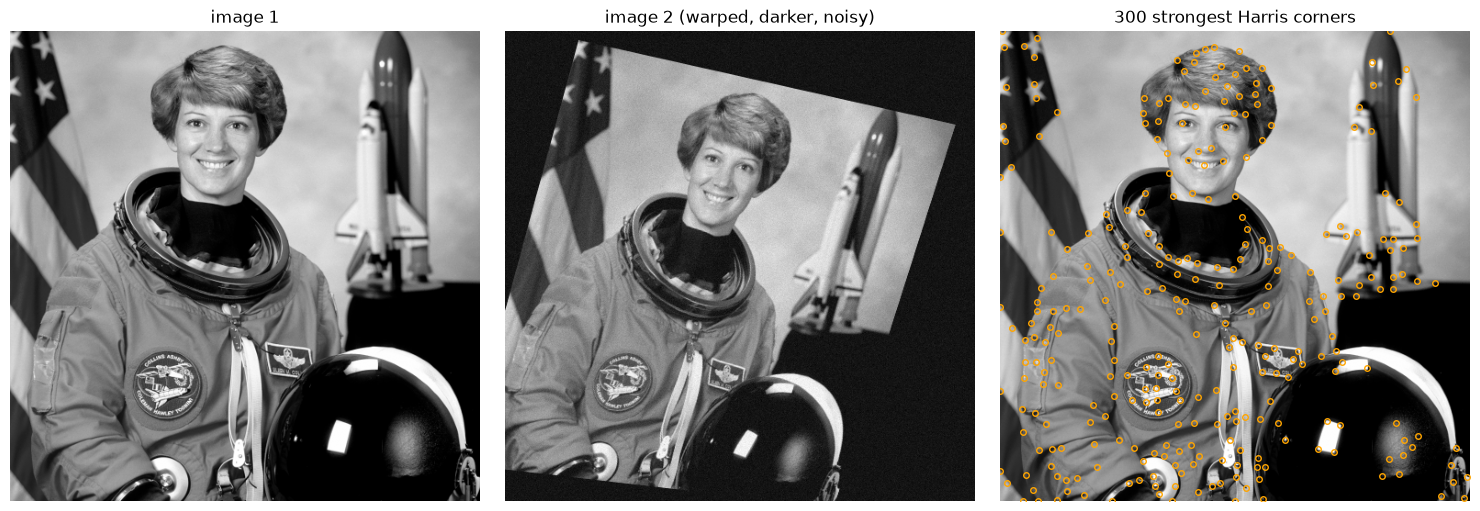

In [6]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

# 1. the two views
axs[0].imshow(img1, cmap="gray")
axs[0].set_title("image 1")
axs[1].imshow(img2, cmap="gray")
axs[1].set_title("image 2 (warped, darker, noisy)")

# 2. Harris corners on image 1
axs[2].imshow(img1, cmap="gray")
axs[2].plot(pts[:, 0], pts[:, 1], "o", ms=4, mfc="none", mec="orange")
axs[2].set_title(f"{len(pts)} strongest Harris corners")

for a in axs:
    a.axis("off")
plt.tight_layout()
plt.show()

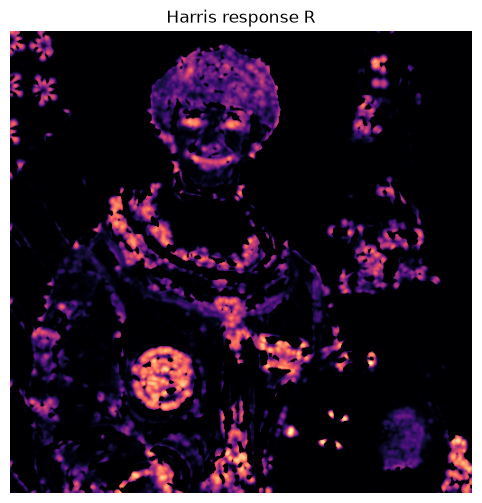

In [7]:
plt.figure(figsize=(6, 6))
plt.imshow(np.log1p(np.maximum(R, 0) * 1e4), cmap="magma")   # log scale: weak corners stay visible
plt.title("Harris response R")
plt.axis("off")
plt.show()

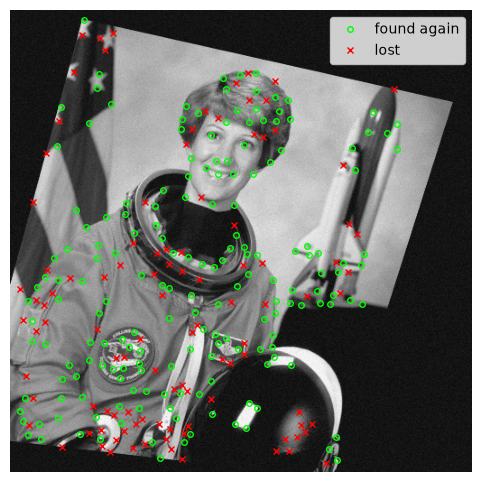

In [8]:
ok = d < 2
proj_in = proj[inside]
plt.figure(figsize=(6, 6))
plt.imshow(img2, cmap="gray")
plt.plot(proj_in[ok, 0], proj_in[ok, 1], "o", ms=4, mfc="none", mec="lime", label="found again")
plt.plot(proj_in[~ok, 0], proj_in[~ok, 1], "x", ms=4, color="red", label="lost")
plt.legend(); plt.axis("off"); plt.show()

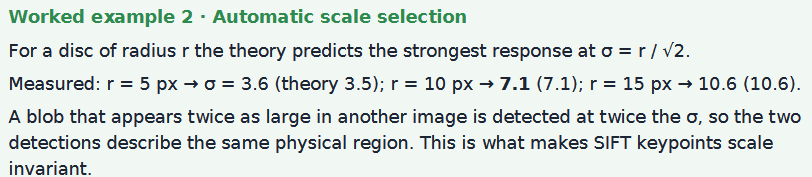

In [9]:
def blob(radius, size=101):
    yy, xx = np.mgrid[:size, :size] - size // 2
    return (xx**2 + yy**2 <= radius**2).astype(np.float32)
sigmas = np.linspace(1, 20, 191)
for radius in [5, 10, 15]:
    img = blob(radius)
    resp = [-(s**2) * cv2.Laplacian(cv2.GaussianBlur(img, (0, 0), s), cv2.CV_32F)[50, 50]
    for s in sigmas]
    best = sigmas[int(np.argmax(resp))]
    print(f"blob radius {radius:2d} px -> strongest response at sigma = {best:.1f} "
    f"(theory r / sqrt(2) = {radius / np.sqrt(2):.1f})")

blob radius  5 px -> strongest response at sigma = 3.6 (theory r / sqrt(2) = 3.5)
blob radius 10 px -> strongest response at sigma = 7.1 (theory r / sqrt(2) = 7.1)
blob radius 15 px -> strongest response at sigma = 10.6 (theory r / sqrt(2) = 10.6)
